# Information-Free Novelty

A tour of the project you can run. The forager simulations here are short so each cell
finishes in under a minute or so. The fitness landscapes are loaded from `results/`,
because computing them took hours on a cluster.

In [1]:
%matplotlib inline
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import Image, display

from scripts.world import World, PATCH_PROFILE
from scripts.agent import Agent
from scripts.fitness import Genome, compute_fitness, evaluate_genome_per_world, eval_seeds
from scripts.params import BASE_PARAMS, ANCESTRAL_GENOME
from scripts.compute_ladder import summarise

warnings.filterwarnings('ignore')   # the ODE solver complains on some steps; harmless
plt.rcParams['figure.dpi'] = 110

## What a patch smells like

The forager never sees a patch's real value. It follows the scent, which is the value
left plus a novelty bonus weighted by its trait `κ`. The mismatch `m` sets how much of
that novelty is honest: at `m = 0` novelty fades as the patch is eaten, at `m = 1`
every patch looks brand new forever.

Below, one forager with `κ = 3` eats its way through a patch. The neuron needs a drive
of 10 to fire, so once the scent drops under that line the forager stops biting.

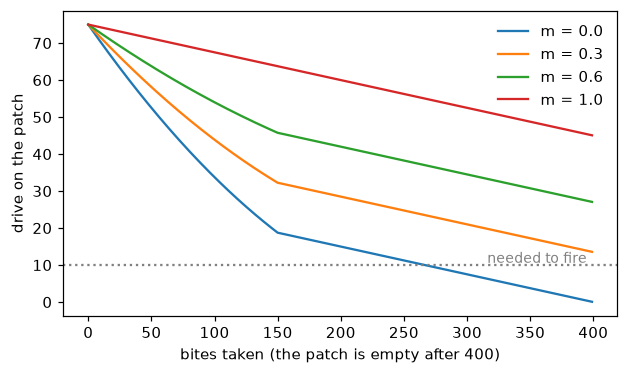

In [2]:
kappa = 3.0
bites = np.arange(400)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for m in (0.0, 0.3, 0.6, 1.0):
    patch = World(rng=np.random.default_rng(0), mismatch_index=m, n_patches=1).patches[0]
    patch.max_utility = patch.current_utility = 40.0
    drive = []
    for _ in bites:
        drive.append(PATCH_PROFILE['A'] * patch.scent(kappa))   # standing on the patch
        patch.deplete(0.1)
    ax.plot(bites, drive, label=f'm = {m}')
ax.axhline(10, color='grey', ls=':')
ax.text(395, 10.6, 'needed to fire', ha='right', color='grey', fontsize=9)
ax.set_xlabel('bites taken (the patch is empty after 400)')
ax.set_ylabel('drive on the patch')
ax.legend(frameon=False, loc='upper right')
plt.show()

At `m = 0.3` and above, even an empty patch stays over the line, so this forager
would keep firing on a patch with nothing left in it.

## One forager, one patch

The forager starts in a corner, wanders until it picks up the scent, then heads in and
starts biting. On the right is its neuron: the membrane potential `V` (each spike is a
bite) and the opportunity cost `β`. Change the genome or `m` and run it again.

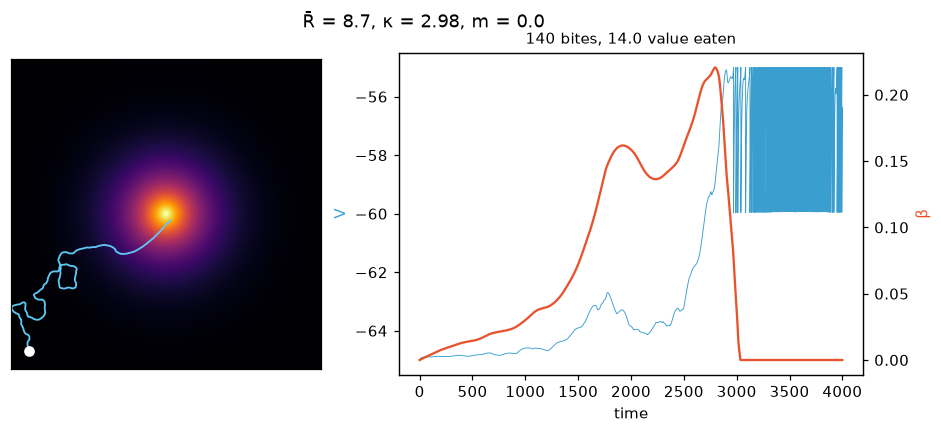

In [3]:
def one_patch(genome, m, t_end=4000, seed=8):
    world = World(rng=np.random.default_rng(seed), mismatch_index=m, n_patches=1,
                  space_initial_patches=False)
    world.patches[0].x = world.patches[0].y = 0.0
    grid = world.compute_grid(0.0)
    agent = Agent(Genome(*genome).to_params(BASE_PARAMS), world,
                  rng=np.random.default_rng(seed), x0=-620, y0=-620)
    return world, grid, agent.simulate((0.0, t_end))


def show_run(world, grid, h, title):
    half = world.world_half
    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={'width_ratios': [1, 1.5]})
    a.imshow(grid, extent=[-half, half, -half, half], origin='lower', cmap='inferno')
    a.plot(h.x, h.y, color='#5ec8f5', lw=1.2)
    a.plot(h.x[0], h.y[0], 'o', color='white')
    a.set_xticks([]); a.set_yticks([])
    b.plot(h.t, h.V, color='#3a9fcf', lw=0.6)
    b.set_xlabel('time'); b.set_ylabel('V', color='#3a9fcf')
    b2 = b.twinx()
    b2.plot(h.t, h.beta_PFC, color='#e8532e')
    b2.set_ylabel('β', color='#e8532e')
    b.set_title(f'{len(h.fire_times)} bites, {h.harvested_utility.sum():.1f} value eaten', fontsize=10)
    fig.suptitle(title)
    plt.show()


genome = ANCESTRAL_GENOME   # (R̄, κ) = (8.7, 2.98), the forager tuned to the ancestral world
m = 0.0
show_run(*one_patch(genome, m), f'R̄ = {genome[0]}, κ = {genome[1]}, m = {m}')

## The same forager, ancestral world vs modern world

Now three patches, which get used up and respawn elsewhere. The forager is the same in
both runs, and so is the map; only `m` differs.

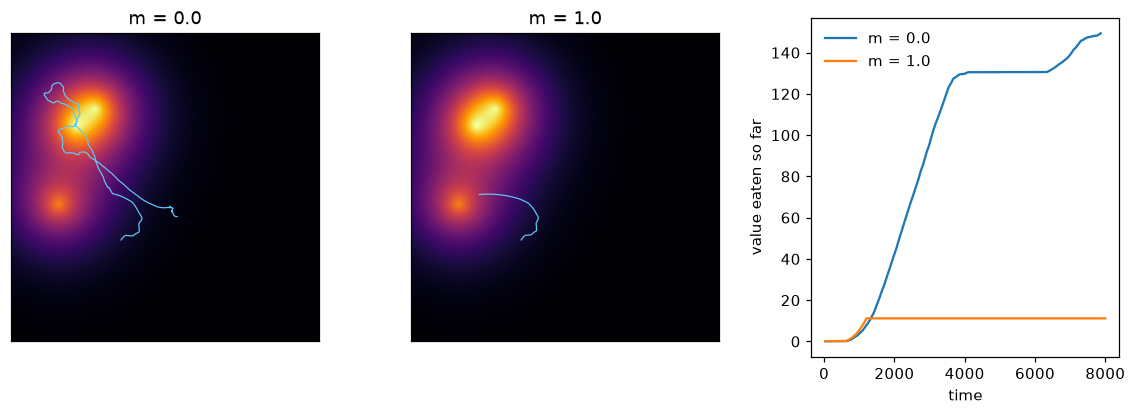

m = 0.0:  fitness +0.78,  1494 bites, 0% of them on an empty patch
m = 1.0:  fitness -0.04,  3916 bites, 97% of them on an empty patch


In [4]:
def three_patches(genome, m, t_end=8000, seed=3):
    world = World(rng=np.random.default_rng(seed), mismatch_index=m, space_initial_patches=False)
    grid = world.compute_grid(0.0)
    agent = Agent(Genome(*genome).to_params(BASE_PARAMS), world, rng=np.random.default_rng(seed))
    return world, grid, agent.simulate((0.0, t_end))


runs = {m: three_patches(ANCESTRAL_GENOME, m) for m in (0.0, 1.0)}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw={'wspace': 0.3})
vmax = max(grid.max() for _, grid, _ in runs.values())
for ax, (m, (world, grid, h)) in zip(axes, runs.items()):
    half = world.world_half
    ax.imshow(grid, extent=[-half, half, -half, half], origin='lower', cmap='inferno',
              vmin=0, vmax=vmax)
    ax.plot(h.x, h.y, color='#5ec8f5', lw=0.8)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'm = {m}')
    axes[2].plot(h.fire_times, np.cumsum(h.harvested_utility), label=f'm = {m}')
axes[2].set_xlabel('time'); axes[2].set_ylabel('value eaten so far')
axes[2].legend(frameon=False)
plt.show()

for m, (world, grid, h) in runs.items():
    wasted = np.mean(h.harvested_utility == 0) if len(h.fire_times) else 0
    print(f'm = {m}:  fitness {compute_fitness(h):+.2f},  {len(h.fire_times)} bites, '
          f'{wasted:.0%} of them on an empty patch')

## The fitness landscape

Each forager has two heritable traits, `R̄` (how rich it expects the world to be) and
`κ` (how much novelty pulls it). Every cell below is one `(R̄, κ)` pair, scored on 8
worlds of 25,000 time units. Bright is fit.

Both traits matter over orders of magnitude, so the grid is log-spaced and drawn on log
axes. Set `log_axes = False` to see it on plain axes.

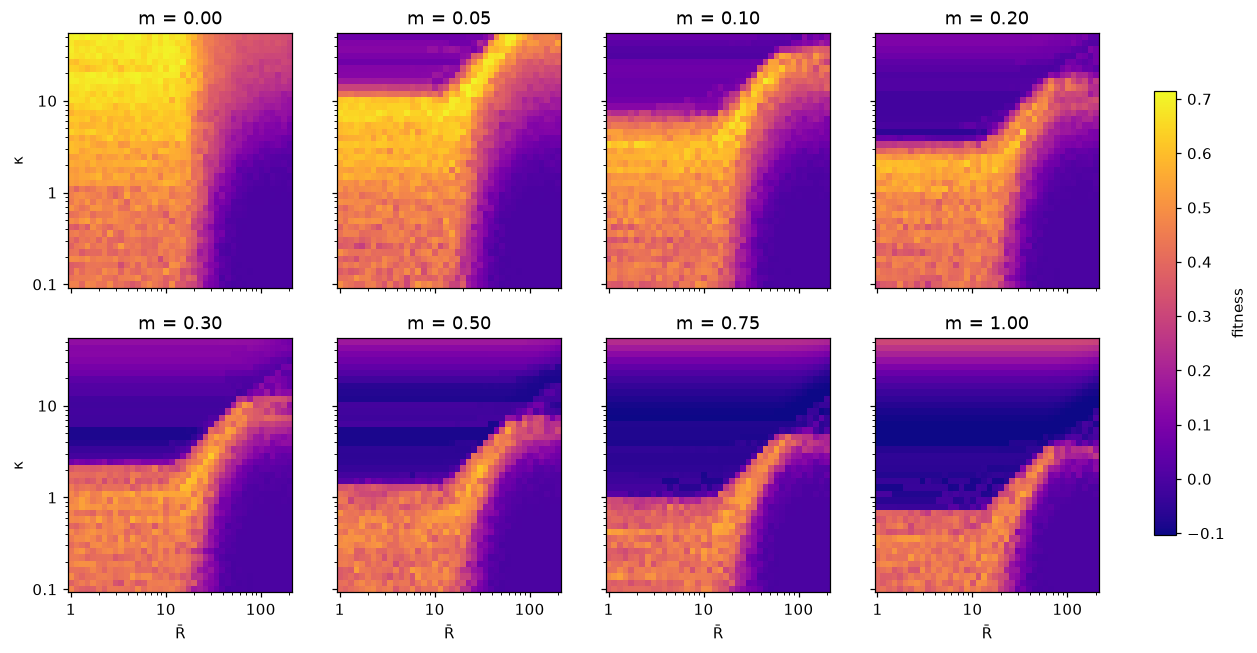

In [5]:
z = np.load('results/ladder_res40/ladder_stack.npz')
R, K, F, F_se, rungs = z['R_bar'], z['kappa'], z['F'], z['F_se'], z['rungs']


def cell_edges(axis):
    a = np.log(axis)
    mid = (a[1:] + a[:-1]) / 2
    return np.exp(np.concatenate([[2 * a[0] - mid[0]], mid, [2 * a[-1] - mid[-1]]]))


log_axes = True

fig, axes = plt.subplots(2, 4, figsize=(13, 6.6), sharex=True, sharey=True)
for ax, f, m in zip(axes.flat, F, rungs):
    im = ax.pcolormesh(cell_edges(R), cell_edges(K), f.T, cmap='plasma',
                       vmin=F.min(), vmax=F.max())
    if log_axes:
        ax.set_xscale('log'); ax.set_yscale('log')
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_title(f'm = {m:.2f}')
for ax in axes[1]:
    ax.set_xlabel('R̄')
for ax in axes[:, 0]:
    ax.set_ylabel('κ')
fig.colorbar(im, ax=axes, fraction=0.02, label='fitness')
plt.show()

The best strategy at each level, over the whole grid and inside the "biological box"
(`R̄ ≤ 25`, `κ ≤ 15`), the part of trait space I treat as plausible. A cell's standard
error between worlds is about 0.05, so neighbours within that are as good as tied.

In [6]:
summarise('results/ladder_res40/ladder_stack.npz')

model=pure-v2  grid 40x40 (log)  box has 24x32 cells
standard error of a cell (between worlds): median 0.051, max 0.118
  mismatch=0.00  best +0.714 at R=1.5 k=50.00  | box best +0.687 at R=1.5 k=13.97
  mismatch=0.05  best +0.709 at R=22.8 k=11.92  | box best +0.709 at R=22.8 k=11.92
  mismatch=0.10  best +0.694 at R=44.9 k=16.39  | box best +0.667 at R=19.9 k=5.37
  mismatch=0.20  best +0.651 at R=34.2 k=4.58  | box best +0.637 at R=8.8 k=2.06
  mismatch=0.30  best +0.627 at R=29.9 k=2.84  | box best +0.608 at R=17.3 k=1.50
  mismatch=0.50  best +0.613 at R=29.9 k=2.06  | box best +0.585 at R=22.8 k=1.28
  mismatch=0.75  best +0.563 at R=15.1 k=0.49  | box best +0.563 at R=15.1 k=0.49
  mismatch=1.00  best +0.547 at R=34.2 k=1.09  | box best +0.536 at R=17.3 k=0.58
ancestral-tuned genome (top 10% of box at mismatch=0.10): ANCESTRAL_GENOME = (8.7, 2.98)


Look up any genome. This finds the nearest cell and prints its score at every level.

In [7]:
def lookup(R_bar, kappa):
    i = np.abs(np.log(R / R_bar)).argmin()
    j = np.abs(np.log(K / kappa)).argmin()
    print(f'nearest cell: R̄ = {R[i]:.1f}, κ = {K[j]:.2f}')
    for m, f, se in zip(rungs, F[:, i, j], F_se[:, i, j]):
        print(f'  m = {m:.2f}   {f:+.2f} ± {se:.2f}')


lookup(*ANCESTRAL_GENOME)

nearest cell: R̄ = 8.8, κ = 2.84
  m = 0.00   +0.60 ± 0.02
  m = 0.05   +0.57 ± 0.04
  m = 0.10   +0.54 ± 0.05
  m = 0.20   +0.42 ± 0.10
  m = 0.30   -0.02 ± 0.05
  m = 0.50   -0.06 ± 0.05
  m = 0.75   -0.06 ± 0.05
  m = 1.00   -0.05 ± 0.05


## The mismatch load

Red is the ancestral-tuned forager, kept fixed as the world changes. Green is the best
forager in the box for each world. Both are re-scored on 32 fresh worlds, so green
isn't just the luckiest cell. The gap is the mismatch load.

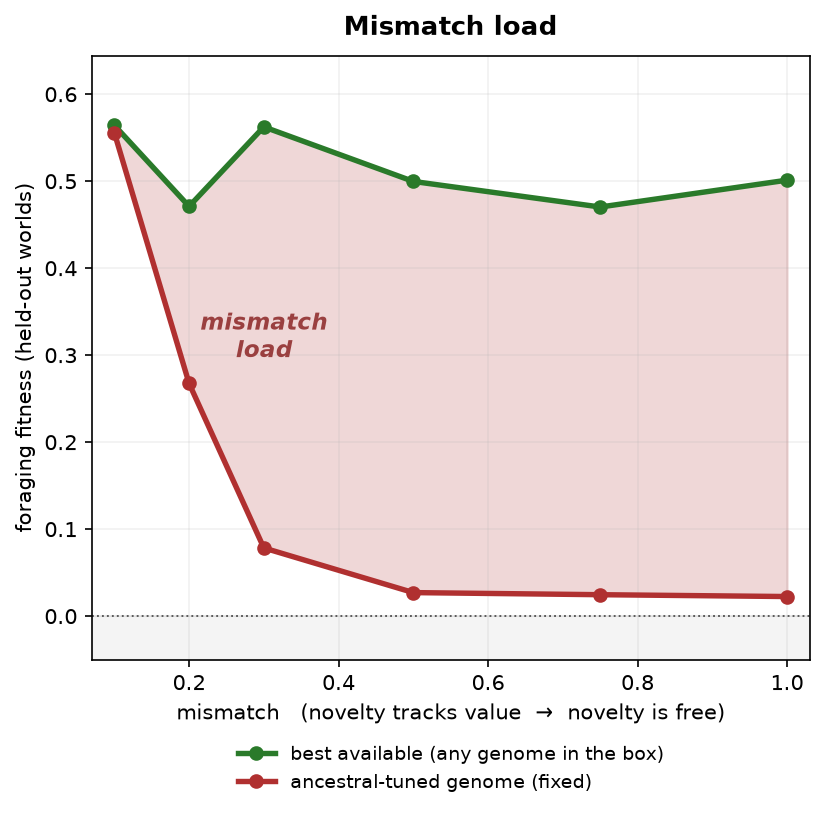

   m   ancestral   best   load
 0.10   +0.556    +0.564  0.009
 0.20   +0.267    +0.471  0.204
 0.30   +0.078    +0.562  0.484
 0.50   +0.027    +0.500  0.473
 0.75   +0.025    +0.470  0.446
 1.00   +0.023    +0.501  0.479


In [8]:
display(Image('results/mismatch_load.png', width=430))

d = np.load('results/mismatch_load_data.npz')
print('   m   ancestral   best   load')
for m, r, g in zip(d['mm'], d['red'], d['green']):
    print(f'{m:5.2f}   {r:+.3f}    {g:+.3f}  {g - r:.3f}')

## Score your own forager

This runs the real fitness function: one run of 25,000 time units per world, as in the
landscape, all in parallel. It takes a minute or two. The landscape averaged 8 worlds per
cell; 2 worlds is a noisier look.

In [9]:
from concurrent.futures import ProcessPoolExecutor

genome = (8.7, 2.98)        # try (17.3, 0.58), the best in the box at m = 1
levels = (0.0, 0.3, 1.0)
n_worlds, t_eval = 2, 25_000

jobs = [(np.array(genome), BASE_PARAMS, [seed], t_eval, 20_000,
         {'mismatch_index': m, 'space_initial_patches': False})
        for m in levels for seed in eval_seeds(n_worlds)]
with ProcessPoolExecutor() as pool:
    scores = np.array([s[0] for s in pool.map(evaluate_genome_per_world, jobs)])

for m, s in zip(levels, scores.reshape(len(levels), n_worlds)):
    print(f'm = {m}:  fitness {s.mean():+.2f}   (per world: {np.round(s, 2)})')

m = 0.0:  fitness +0.64   (per world: [0.58 0.7 ])
m = 0.3:  fitness -0.06   (per world: [-0.09 -0.03])
m = 1.0:  fitness -0.08   (per world: [-0.13 -0.03])


## More

- `python -m scripts.render_forager_video` makes a phone-sized video of the forager at
  work (`--mismatch_index 1.0` for the modern world).
- `run_landscape.sh` is the cluster job that computed the landscape.
- The papers behind each part of the model are in `docs/references.md`.